### Building Chatbot with multiple tools using langgraph

## Aim is to create a chatbot with tool capabilities from arxiv, wikipidia search and some functions

In [359]:
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper

In [360]:
# import inspect
# api_wrapper_arxiv = ArxivAPIWrapper(top_k_results=2, doc_content_chars_max=500)
# arxiv = ArxivQueryRun(api_wrapper=api_wrapper_arxiv)
# print(arxiv.name)
# print(inspect.getsource(ArxivAPIWrapper))

In [361]:
# arxiv.invoke("Attention is all you need")


In [362]:
import requests
import xml.etree.ElementTree as ET

def search_arxiv(query, max_results=2):
    response = requests.get(
        "https://export.arxiv.org/api/query",
        params={
            "search_query": f'all:"{query}"',
            "start": 0,
            "max_results": max_results
        },
        timeout=30
    )
    response.raise_for_status()

    root = ET.fromstring(response.content)
    ns = {"atom": "http://www.w3.org/2005/Atom"}

    papers = []

    for entry in root.findall("atom:entry", ns):
        papers.append({
            "title": entry.findtext(
                "atom:title", default="", namespaces=ns
            ).strip(),
            "summary": entry.findtext(
                "atom:summary", default="", namespaces=ns
            ).strip(),
            "url": entry.findtext(
                "atom:id", default="", namespaces=ns
            )
        })

    return papers

In [363]:
papers = search_arxiv("Attention is all you need")

for paper in papers:
    print("Title:", paper["title"])
    print("URL:", paper["url"])
    print("Abstract:", paper["summary"][:500])
    print("-" * 50)

Title: Tool Attention Is All You Need: Dynamic Tool Gating and Lazy Schema Loading for Eliminating the MCP/Tools Tax in Scalable Agentic Workflows
URL: http://arxiv.org/abs/2604.21816v1
Abstract: The Model Context Protocol (MCP) has become a common interface for connecting large language model (LLM) agents to external tools, but its reliance on stateless, eager schema injection imposes a hidden per-turn overhead the MCP Tax or Tools Tax that practitioner reports place between roughly 10k and 60k tokens in typical multi-server deployments. This payload inflates the key-value cache, is associated with reasoning degradation as context utilization approaches published fracture points around 
--------------------------------------------------
Title: Attention Is All You Need
URL: http://arxiv.org/abs/1706.03762v7
Abstract: The dominant sequence transduction models are based on complex recurrent or convolutional neural networks in an encoder-decoder configuration. The best performing models 

In [364]:
api_wrapper_wiki = WikipediaAPIWrapper(
    top_k_results=1,
    doc_content_chars_max=500
)

wiki = WikipediaQueryRun(api_wrapper=api_wrapper_wiki)

print(wiki.name)
print(wiki.invoke("Machine Learning"))

wikipedia
Page: Machine learning
Summary: Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from  data and generalize to unseen data, and thus perform tasks without being explicitly programmed.
Statistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, focusing on exploratory data analysis (EDA) through unsupervised learning.
From 


In [365]:
from dotenv import load_dotenv
load_dotenv()

import os

os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")


In [366]:
from langchain_community.tools.tavily_search import TavilySearchResults

tavily = TavilySearchResults()

tavily.invoke("What are the latest RAG techniques, and which papers discuss them?")


[{'title': 'Advancements in RAG: A Comprehensive Survey of Techniques and Applications',
  'url': 'https://medium.com/@sahin.samia/advancements-in-rag-a-comprehensive-survey-of-techniques-and-applications-b6160b035199',
  'content': 'CommunityKG-RAG Paper: CommunityKG-RAG: Zero-Shot Retrieval-Augmented Generation with Knowledge Graphs\n   MemoRAG Paper: MemoRAG: Dual-System Architecture for Ambiguous Knowledge Retrieval\n   NLLB-E5 Paper: NLLB-E5: Scalable Multilingual Retrieval for Low-Resource Languages\n   Speculative RAG Blog: Speculative RAG: Enhancing Retrieval-Augmented Generation through Drafting\n   Stochastic RAG Paper: Stochastic RAG: End-to-End Retrieval-Augmented Generation through Expected Utility Maximization\n   Semantic Router: Semantic Router GitHub Repository [...] Multimodal RAG: Retrieval-augmented multimodal language modeling (Multimodal RAG Paper) integrates text, images, and videos, enhancing cross-modal retrieval. RULE (RULE Paper) is a multimodal RAG for medic

In [367]:
def add(a: int, b: int) -> int:
    """Add two numbers."""
    return a + b


In [368]:
tools = [tavily,wiki,add]

In [ ]:
from langchain_groq import ChatGroq
from langchain_core.messages import AIMessage,HumanMessage,ToolMessage
from pprint import pprint
from langchain.agents import create_agent

llm_groq = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens = 200

)

# # Create the agent
# agent = create_agent(
#     model=llm_groq,
#     tools=tools,
   # system_prompt="You are a helpful assistant specialized in regional updates."

# )

# Yes! create_agent() automatically handles tool calls, ToolNode, ToolMessage, and conditional routing internally using LangGraph.
# Here's exactly what happens:
# Component	What create_agent() does
# LLM call	Calls your Groq model
# tool_calls	Reads tool requests generated by the LLM
# tools_condition	Performs equivalent conditional routing automatically
# ToolNode	Executes the requested tools
# ToolMessage	Stores each tool's result as a message
# Agentic loop	Sends tool results back to the LLM
# Final answer	Returns the LLM's response when no more tool calls are requested

# # Ask a question
# result = agent.invoke({
#     "messages": [
#         HumanMessage(content="What is machine learning? Search using wiki tool")
#     ]
# })

# Print the final answer

llm_with_tools = llm_groq.bind_tools(tools)

In [370]:

# for message in result["messages"]:
#     print(f"\nMessage type: {type(message).__name__}")
#     print("Content:", message.content)

#     # Check which tools the LLM requested
#     if isinstance(message, AIMessage) and message.tool_calls:
#         for call in message.tool_calls:
#             print("Tool called:", call["name"])
#             print("Arguments:", call["args"])

#     # Check the result returned by a tool
#     if isinstance(message, ToolMessage):
#         print("Tool result:", message.content)
#         print("Tool call ID:", message.tool_call_id)


In [371]:
llm_with_tools.invoke([HumanMessage(content=f"What is recent news in AI ? Call tool tavily")])
# print(tools)# 

AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '7wzww0bht', 'function': {'arguments': '{"query":"recent news in AI 2024"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 481, 'total_tokens': 518, 'completion_time': 0.110052939, 'completion_tokens_details': None, 'prompt_time': 0.036550124, 'prompt_tokens_details': None, 'queue_time': 0.221112352, 'total_time': 0.146603063}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12ac5-c889-7640-bb68-fdf4da559260-0', tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'recent news in AI 2024'}, 'id': '7wzww0bht', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 481, 'output_tokens': 37, 'total_tokens': 518})

In [372]:
from langchain_core.messages import HumanMessage, ToolMessage

# 1. User question
human_message = HumanMessage(
    content="What is recent news in AI? Call tool tavily"
)

# 2. LLM requests a tool
response = llm_with_tools.invoke([human_message])

print("AI response:")
print(response)

print("\nTool calls requested:")
print(response.tool_calls)

# 3. Execute the requested tool
call = response.tool_calls[0]
tool_result = tavily.invoke(call["args"])

print("\nTool result:")
print(tool_result)

# 4. Create ToolMessage
tool_message = ToolMessage(
    content=str(tool_result),
    tool_call_id=call["id"]
)

print("\nTool message:")
print(tool_message)

# 5. Send tool result back to the LLM
final_response = llm_with_tools.invoke([
    human_message,
    response,
    tool_message
])

print("\nFinal answer:")
print(final_response.content)

AI response:
content='' additional_kwargs={'tool_calls': [{'id': 'cqnghq7q0', 'function': {'arguments': '{"query":"recent news in AI"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 481, 'total_tokens': 513, 'completion_time': 0.09354051, 'completion_tokens_details': None, 'prompt_time': 0.033849762, 'prompt_tokens_details': None, 'queue_time': 0.045051708, 'total_time': 0.127390272}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a12ac5-ca6d-7e22-8a52-4a5801eb1cd5-0' tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'recent news in AI'}, 'id': 'cqnghq7q0', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 481, 'output_tokens': 32, 'total_tokens': 513}

Tool calls requested:
[{'name': 'tavily_search_results_j

### Now lets create ChatBot graph

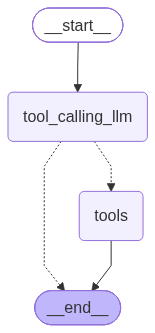

In [374]:
from IPython.display import Image,display
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition   
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph.message import add_messages
from langchain_core.messages import AnyMessage




class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]






### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}


builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools", END)


graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [376]:
messages=graph.invoke({"messages":HumanMessage(content="What is latest oracel news? Use tavily tool")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is latest oracel news? Use tavily tool
================================== Ai Message ==================================
Tool Calls:
  tavily_search_results_json (mfwy4kf85)
 Call ID: mfwy4kf85
  Args:
    query: latest Oracle news
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "News and Press Releases | Oracle News", "url": "https://www.oracle.com/news", "content": "# Oracle News\n\n## Share:\n\n### Select your country/region\n\n#### Americas\n\n#### Asia Pacific\n\n#### Europe\n\n#### Middle East\n\n## Oracle Extends Fusion Agentic Applications with Introduction of Fusion Claw\n\n### Oracle Health Advances Revenue Cycle Management with AI\n\n### Oracle to Advance Cancer Care with New Oncology EHR\n\n### Real-World Data and AI Capabilities in Oracle Life Sciences Data Intelligence Help Accelerate Clinical Research and Comm